### IC healpix map generation

We will use this to generate an IC map at a RA, DEC, and mjd of a given size. 

My goal is to use it to test the Healpix quering with LSST alerts

In [1]:
import sys
sys.path.insert(1, '/Users/cristozilleruelo/Rubicube-Ampel-HU-astro/Rubicube/')


from astropy.time import Time
import astropy.units as u
import numpy as np
import healpy as hp
import mhealpy as mhp

from ic_visualization import plot_full_map
from ic_processing import read_map


/Users/cristozilleruelo/.local/share/mamba/envs/AMPEL/lib/python3.14/site-packages/ligo/skymap/io/events/ligolw.py:26: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
ra = 90
dec = 0
mjd = Time("2026-11-19")
mjd < mjd + 5 * u.s

True

In [3]:
from hop import Stream
from hop.io import StartPosition
#https://hop-client.readthedocs.io/en/latest/user/quickstart.html

stream = Stream(start_at=StartPosition.EARLIEST, until_eos=True)
alerts = []
with stream.open("kafka://kafka.scimma.org/gcn.notices.icecube.gold_bronze_track_alerts", "r") as s:
    for message in s:
         # print(message.content)
        alerts.append(message.content)

Generate a 1-pixel map at a location

nside:  8


(<matplotlib.image.AxesImage at 0x11e775090>, <Mollview: >)

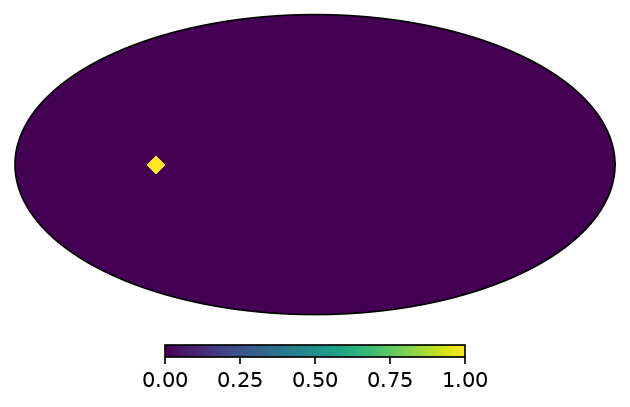

In [16]:
nsides = [2 ** n for n in  range(10)]
nside = nsides[3] #choice of resolution
print('nside: ', nside)
pixel = hp.ang2pix(nside, ra, dec, lonlat=True, nest=True)
# pixel_around = [hp.ang2pix(nside, ra + 1, dec, lonlat=True, nest=True),
#                 hp.ang2pix(nside, ra -1, dec, lonlat=True, nest=True),
#                 hp.ang2pix(nside, ra, dec + 1, lonlat=True, nest=True),
#                 hp.ang2pix(nside, ra, dec - 1, lonlat=True, nest=True),
# ]

data = np.zeros(hp.nside2npix(nside))
data[pixel] += 1
# for pixel_ar in  pixel_around:
#     data[pixel_ar] += 50 

counts = np.zeros(hp.nside2npix(nside))
np.add.at(counts, pixel, 1)

# Probability per pixel -> probability density in 1 / deg^2
pixarea_deg2 = hp.nside2pixarea(nside, degrees=True)
if counts.sum() > 0:
    prob_density_deg2 = (counts / counts.sum()) / pixarea_deg2
else:
    prob_density_deg2 = counts



healpix_map = mhp.HealpixMap(data=data, nside=nside, scheme='NESTED', density=True)
# uniq = healpix_map.uniq
# print(uniq)
# img = healpix_map.get_wcs_img(ax)#, coord = coord, rasterize = rasterize)

#in a boolean map of values 0 or 1, level=0.5 is identified when the map sharply passes from 0 to 1, which works for outlining the pixels
# im = ax.contour(img, levels=[0.5], colors=['green'], linestyles=['solid']) #nested=True,

healpix_map.plot()

Now we need to save the alert in a gz file so it can be read in through ampel. 

In [17]:
# ipix_nested = np.arange(hp.nside2npix(nside))
# if healpix_map.scheme.upper() != "NESTED":
#     # If your map is RING, reorder pixel indices so index i matches NESTED pixel i
#     ipix_nested = hp.ring2nest(nside, ipix_nested)

# uniq = 4 * (nside**2) + ipix_nested

# healpix_map.write_map(
#     test_path,
#     extra_maps=uniq,
#     column_names=["PROBDENSITY", "UNIQ"],
#     overwrite=True,
# )

1


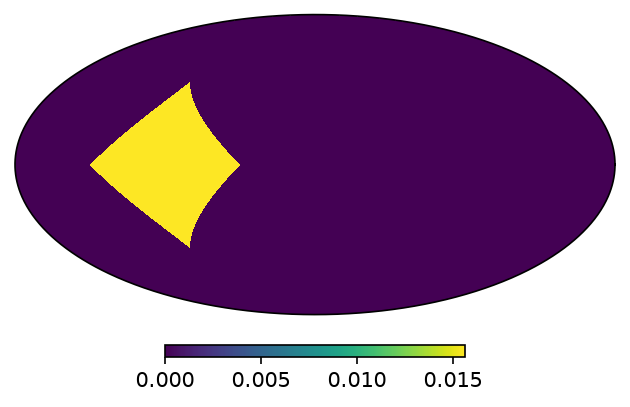

In [ ]:
test_path = '/Users/cristozilleruelo/Desktop/test_map.fits'

moc_map = healpix_map.to_moc(max(healpix_map))
moc_map.write_map(test_path, 
                      column_names="PROBDENSITY",
                      overwrite=True)
# healpix_map.write_map("skymap.fits", column_names="PROBDENSITY", overwrite=True)
moc_map.plot()
print(moc_map.nside)

### Reading the map with our ampel functions

In [10]:
skymap = read_map(test_path, add_units=True)
skymap

{'skymap': <QTable length=12>
  UNIQ  PROBDENSITY  
           1 / sr    
 int64    float64    
 ----- --------------
     4            0.0
     5            0.0
     6            0.0
     7            0.0
     8            0.0
     9 0.018310546875
    10            0.0
    11            0.0
    12            0.0
    13            0.0
    14            0.0
    15            0.0,
 'header': XTENSION= 'BINTABLE'           / binary table extension                         
 BITPIX  =                    8 / array data type                                
 NAXIS   =                    2 / number of array dimensions                     
 NAXIS1  =                   16 / length of dimension 1                          
 NAXIS2  =                   12 / length of dimension 2                          
 PCOUNT  =                    0 / number of group parameters                     
 GCOUNT  =                    1 / number of groups                               
 TFIELDS =                    2 /

In [8]:
#compare to the other skymaps
alert = alerts[-1]
skymap_ic = read_map(alert['healpix_url'], add_units=False)
skymap_ic

{'skymap': <QTable length=5385>
   UNIQ       PROBDENSITY     
                 1 / sr       
  int64         float64       
 ------- ---------------------
    1024                   0.0
    1025                   0.0
    1026  5.69849380421511e-16
    1027 8.898926952396848e-15
    1028 6.758678698022848e-16
    1029                   0.0
    1030                   0.0
    1031  4.43952424281899e-16
    1032                   0.0
     ...                   ...
 7553027    1084.0910694496508
 7553032     1119.284747023773
 7553033     1085.056570633602
 7553034    1112.2312795188514
 7553035    1079.5643694853259
 7553056    1098.5100285672302
 7553057    1067.6521310733874
 7553058    1078.3258682407602
 7553059    1049.4854621643028,
 'header': XTENSION= 'BINTABLE'           / binary table extension                         
 BITPIX  =                    8 / array data type                                
 NAXIS   =                    2 / number of array dimensions                    

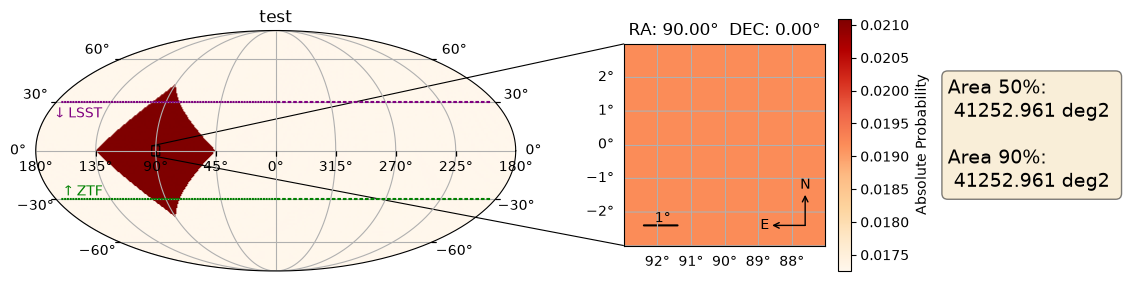

('test.png',
 <Quantity 41252.96124942 deg2>,
 <mhealpy.containers.healpix_map.HealpixMap at 0x11e257950>)

In [11]:
plot_full_map(skymap, save_dir='')

### TEst with DESY assistant

In [ ]:
def generate_r_minus_2_moc_map(ra_center, dec_center, nside_base=32, max_depth=10):
    """
    Generate a MOC healpix map with an r^-2 profile centered at (ra_center, dec_center).
    The map integrates to 1 and has units of probability density (1/deg²).

    Parameters:
    -----------
    ra_center : float
        Right Ascension (degrees) of the center.
    dec_center : float
        Declination (degrees) of the center.
    nside_base : int, optional
        Base NSIDE for the MOC (default: 32).
    max_depth : int, optional
        Maximum depth for the MOC refinement (default: 10).

    Returns:
    --------
    moc_map : mhealpy.MOC
        A MOC map with the r^-2 profile, normalized to integrate to 1.
    """

    # Convert center coordinates to radians for healpy
    ra_center_rad = np.radians(ra_center)
    dec_center_rad = np.radians(dec_center)

    # Define a fine-resolution healpix grid for sampling the r^-2 profile
    nside_fine = 2 ** max_depth  # High resolution for accurate integration
    npix_fine = hp.nside2npix(nside_fine)
    pix_area_deg2 = hp.nside2pixarea(nside_fine, degrees=True)  # Pixel area in deg²

    # Compute angular distances from the center for all pixels
    theta, phi = hp.pix2ang(nside_fine, np.arange(npix_fine), lonlat=True)

    vec1 = hp.dir2vec(ra_center_rad, dec_center_rad, lonlat=True)
    vec2 = hp.dir2vec(phi, theta, lonlat=True)
    # ang_dist = hp.rotator.angdist(ra_center_rad, dec_center_rad, lonlat=True)#, phi, theta)
    ang_dist = hp.rotator.angdist(vec1, vec2, lonlat=False) * u.rad  


    # Avoid division by zero at the center (r=0)
    ang_dist[ang_dist == 0] = 1e-10 * u.rad  # Small non-zero value
    # Compute the r^-2 profile (unnormalized)
    r = ang_dist.to(u.deg).value  # Distance in degrees
    profile = 1.0 / (r ** 2)  # Unnormalized r^-2 profile

    # Normalize the profile so the integral over the sphere is 1
    total_integral = np.sum(profile) #* pix_area_deg2
    profile_normalized = profile / total_integral

    # Assign the normalized profile to a fine-resolution map
    fine_map = np.zeros(npix_fine)
    fine_map[:] = profile_normalized

    # Convert the fine-resolution map to a MOC
    # Threshold the map to retain significant pixels (avoids numerical noise)
    threshold = 1e-10  # Adjust as needed
    fine_map[fine_map < threshold] = 0.0

    # Create a MOC from the fine map
    moc_map = mhp.HealpixMap(data=fine_map, nside=nside_fine, scheme='NESTED').to_moc(max(fine_map))

    return moc_map

(<matplotlib.image.AxesImage at 0x123ff8590>, <Mollview: >)

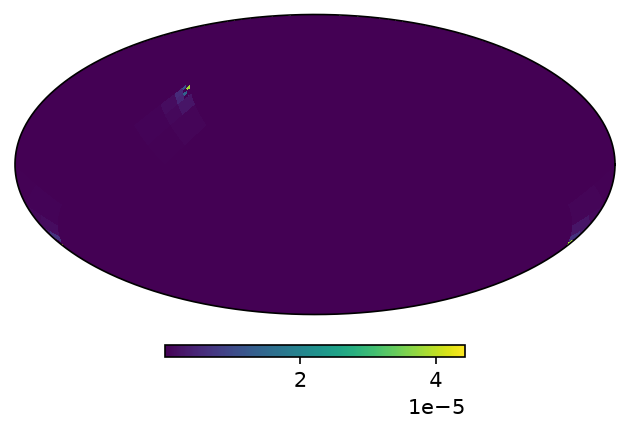

In [ ]:
m = generate_r_minus_2_moc_map(0, 0)
m.plot()

In [ ]:
test_path = '/Users/cristozilleruelo/Desktop/test_map.fits'

m.write_map(test_path, 
            column_names="PROBDENSITY",
            overwrite=True)

In [ ]:
skymap = read_map(test_path, add_units=True)
skymap

{'skymap': <QTable length=75>
   UNIQ        PROBDENSITY     
                  1 / sr       
  int64          float64       
 -------- ---------------------
        4  0.008824527518433167
        5  0.011195836238451275
        6  0.014953595369514749
        7  0.021834283078004744
        8   0.03867699264357818
       11   0.03867699264357821
       12   0.02183428307800306
       13  0.014953595369515071
       14  0.011195836238451518
      ...                   ...
  2621955 0.0001772849653085411
 10479616  0.043968272642423666
 10479617  0.006711021888584082
 10479618  0.001894644875577173
 10479619 0.0008627174533233709
 10487808  0.043968272642423666
 10487809  0.006711021888584082
 10487810  0.001894644875577173
 10487811 0.0008627174533233709,
 'header': XTENSION= 'BINTABLE'           / binary table extension                         
 BITPIX  =                    8 / array data type                                
 NAXIS   =                    2 / number of array dimension

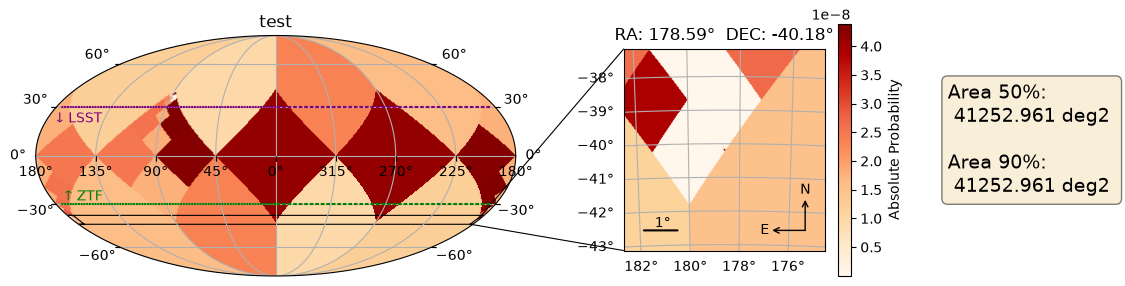

In [ ]:
_ = plot_full_map(skymap, save_dir='')

### Angela's code from IceCube

In [17]:
def gaus_prob(dec, ra, dec_in, ra_in, one_sig_err):
        ''' 
        Adapted from https://github.com/icecube/realtime/blob/185383567df283e768e5944985306528ae0be3d3/realtime_scripts/resources/scripts/kafka_gcn_trackalert_test.py#L143
            Credit: Erik Blaufus and Angela Zegarelli
        '''
        #p(x)=1/(2πσ²)D/2 * exp(-||x||²/2σ²)
        ang_sep = ang_dist(dec, ra, dec_in, ra_in)
        prob = (1/(2*np.pi*one_sig_err**2)) * np.exp(-1.0*(ang_sep**2)/(2*one_sig_err**2))
        return prob

def IndexToDeclRa(nside, index):
    ''' 
    Adapted from https://github.com/icecube/realtime/blob/185383567df283e768e5944985306528ae0be3d3/realtime_scripts/resources/scripts/kafka_gcn_trackalert_test.py#L143
    Credit: Erik Blaufus and Angela Zegarelli
    '''
    theta,phi=hp.pixelfunc.pix2ang(nside,index)
    #return -np.degrees(theta-np.pi/2.),np.degrees(np.pi*2.-phi)
    return -(theta-np.pi/2.), phi

def ang_dist(dec1,ra1,dec2,ra2):
    '''
        Adapted from https://github.com/icecube/realtime/blob/185383567df283e768e5944985306528ae0be3d3/realtime_scripts/resources/scripts/kafka_gcn_trackalert_test.py#L143
        Credit: Erik Blaufus and Angela Zegarelli
    '''
    a = (np.sin((dec2 - dec1)/2.0))**2
    b = np.cos(dec1)*np.cos(dec2)
    c = (np.sin((ra2 - ra1)/2.0))**2
    ang_diff = 2.0*np.arcsin(np.sqrt((a + b * c)))
    return ang_diff


def make_and_post_healpix(alert=None, alert_type ="Gold", nside=512, save_path='sim_alert.fits'):
#from mhealpy import HealpixBase, HealpixMap
    '''
    Adapted from https://github.com/icecube/realtime/blob/185383567df283e768e5944985306528ae0be3d3/realtime_scripts/resources/scripts/kafka_gcn_trackalert_test.py#L143
    Credit: Erik Blaufus and Angela Zegarelli

    alert: dict: {
    'name': 
    'ra': 
    'dec':
    'ra_dec_error': 
    't_mjd': 
    'stream': 'GOLD' or 'BRONZE',
    }
    '''
    if alert is None:
            return None
    dec_in = np.radians(alert['dec'])
    theta_in = -dec_in + np.pi/2.0
    ra_in  = np.radians(alert['ra'])
    one_sig_err = np.radians(alert['ra_dec_error'])  # in radians

    npix = hp.nside2npix(nside) # Calculate total number of pixels for given nside

    # Create an empty map (e.g., filled with zeros)
    healpix_map = np.zeros(npix)
    # create a MUC map as well
    mEq = mhp.HealpixBase(order = 12, scheme='RING',  coordsys='C')
    disc_pix = mEq.query_disc(mhp.ang2vec(theta_in, ra_in), np.radians(2.0))
    m = mhp.HealpixMap.moc_from_pixels(mEq.nside, disc_pix, coordsys='C',density=True)

    for i in range(npix):
        dec, ra = IndexToDeclRa(nside, i)
        healpix_map[i] = gaus_prob(dec, ra, dec_in, ra_in, one_sig_err)


    for pix in range(m.npix):
        theta,phi= m.pix2ang(pix)
        dec,ra = -(theta-np.pi/2.),phi
        m[pix] = gaus_prob(dec, ra, dec_in, ra_in, one_sig_err)

    m_normalized_map = m/np.sum(m)
    # now make into a normalized density...
    for pix in range(m.npix):
        m_normalized_map[pix] = m_normalized_map[pix]/m_normalized_map.pixarea(pix).to_value()



    #normalize to 1.0 over all pixels    
    hp_normalized_map = healpix_map/(np.sum(healpix_map)*hp.pixelfunc.nside2pixarea(nside))
    #update the headers
    _scale_90 = 2.56708542 # GFU scale factor for 50% to 90% containment
    extra_header = [
            # ('RUNID',alert['id'][0].split('_')[0]),
            # ('EVENTID',alert['id'][0].split('_')[1]),
            ('SENDER', 'Simulated AMPEL Map'),
            ('DATE-OBS', str(alert['t_mjd']),'UTC date of the observation'),
            ('MJD-OBS',  alert['t_mjd'].mjd,'modified Julian date of the observation'),
            # ('EVENT-TYPE', alert['pipeline'],'Event Type'),
            ('ALERT-STREAM', alert['stream'], 'Alert Stream'),
            ('RA', alert['ra'],'Degree'),
            ('DEC', alert['dec'],'Degree'),
            ('RA_ERR_PLUS_50', alert['ra_dec_error']/_scale_90,'50% containment error high'),
            ('RA_ERR_MINUS_50', alert['ra_dec_error']/_scale_90,'50% containment error low'),
            ('DEC_ERR_PLUS_50', alert['ra_dec_error']/_scale_90,'50% containment error high'),
            ('DEC_ERR_MINUS_50', alert['ra_dec_error']/_scale_90,'50% containment error low'),
            ('RA_ERR_PLUS_90', alert['ra_dec_error'],'90% containment error high'),
            ('RA_ERR_MINUS_90', alert['ra_dec_error'],'90% containment error low'),
            ('DEC_ERR_PLUS_90', alert['ra_dec_error'],'90% containment error high'),
            ('DEC_ERR_MINUS_90', alert['ra_dec_error'],'90% containment error low'),
            ('CONTOUR_AREA_50', np.pi*(alert['ra_dec_error']/_scale_90)**2, '50% contour area (sqdeg)'),
            ('CONTOUR_AREA_90', np.pi*(alert['ra_dec_error'])**2, '90% contour area (sqdeg)')
            ]
    
    #write out the files
    # base_filename = alert['event_name'][0] + '_skymap_probdensity'
    # std_healpix_name = base_filename + '_flat.fits.gz'
    # mhealpix_name = base_filename + '_multiorder.fits.gz'

    save_path = f'{alert['name']}_simulated_test.fits'
    # hp.write_map('/tmp/' + std_healpix_name, hp_normalized_map, column_names=["PROB"], 
    #                 extra_header=extra_header, column_units= 'pix-1', overwrite=True)
    # hp.write_map(save_path, columnames=['PROBDENSITY'], extra_header=extra_header, column_units=['pix-1'], 
    #              overwrite=True)
    m_normalized_map.write_map(save_path, column_names=["PROBDENSITY"], 
                                extra_header=extra_header, overwrite=True)
    return m_normalized_map, save_path

In [18]:
alert_to_simulate =  {
    'name': 'TEST',
    'ra': 200,
    'dec': 0,
    'ra_dec_error': 0.5,
    't_mjd': Time("2026-11-19"),
    'stream': 'GOLD',
    }

In [19]:
m_sim, m_path = make_and_post_healpix(alert=alert_to_simulate, 
                                     nside=512)


(<matplotlib.image.AxesImage at 0x11f5f96a0>, <Mollview: >)

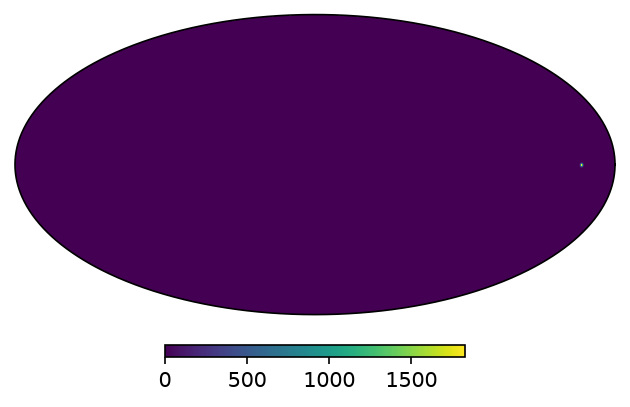

In [20]:
m_sim.plot()

In [23]:
skymap = read_map(m_path, add_units=True)

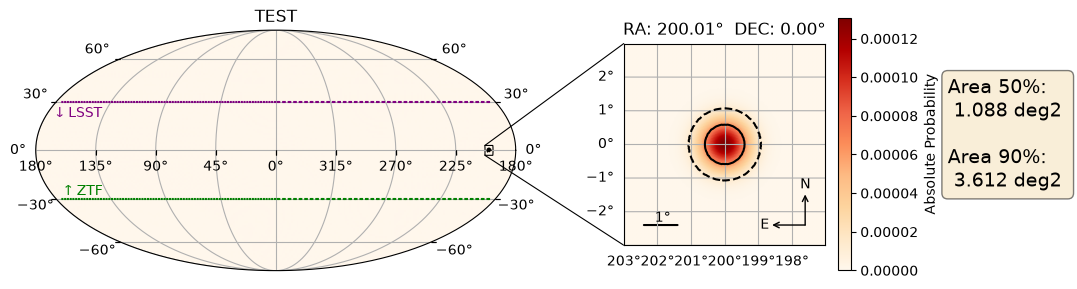

('TEST.png',
 <Quantity 3.61248705 deg2>,
 <mhealpy.containers.healpix_map.HealpixMap at 0x12029d480>)

In [24]:
plot_full_map(skymap, save_dir='')